# 3.8 Two attribute-prediction branches

This notebook compares the two image-only prediction branches implemented on top of the learned visual–semantic embedding:

1. **Schema-guided heads:** manually organized Vietnamese attribute groups trained from title-derived weak labels.
2. **Discovered-concept heads:** automatically formed spatial–semantic clusters, followed by filtering to standardized visual groups.

Both branches use the same frozen image features and category-specific VSE. Their softmax scores and acceptance thresholds are uncalibrated. All emitted attributes are hypotheses requiring review, not validated ground truth.

In [1]:
from pathlib import Path
import json, collections, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT=Path.cwd()
if not (ROOT/'fashion_vn').exists(): ROOT=ROOT.parent
SCHEMA_DIR=ROOT/'outputs/predictions_set_v2_schema'; DISC_DIR=ROOT/'outputs/predictions_set_v2_discovered'
MODEL_ROOT=ROOT/'models/local_resnet18_set_v2'; FIG_DIR=ROOT/'outputs/figures/prediction_branches'
FIG_DIR.mkdir(parents=True,exist_ok=True)
COLORS={'schema':'#386CB0','discovered':'#E68600','green':'#59A14F','red':'#CC4F4F','purple':'#8E63B5','gray':'#929292'}
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':12,'axes.labelsize':11,'figure.titlesize':16})
def read_jsonl(path):
    with path.open(encoding='utf-8') as f: return [json.loads(line) for line in f]
def savefig(fig,stem):
    fig.savefig(FIG_DIR/f'{stem}.png',dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(FIG_DIR/f'{stem}.svg',bbox_inches='tight',facecolor='white')
    plt.show(); plt.close(fig)
schema_summary=json.loads((SCHEMA_DIR/'summary.json').read_text())
disc_summary=json.loads((DISC_DIR/'summary.json').read_text())
schema_rows=read_jsonl(SCHEMA_DIR/'products.jsonl'); disc_rows=read_jsonl(DISC_DIR/'products.jsonl')
schema_by_id={r['product_id']:r for r in schema_rows}; disc_by_id={r['product_id']:r for r in disc_rows}
assert schema_by_id.keys()==disc_by_id.keys()
print(f"Loaded {len(schema_rows):,} products per branch")
print('Threshold/margin:',schema_summary['threshold'],schema_summary['margin'])

Loaded 10,798 products per branch
Threshold/margin: 0.7 0.15


## 3.8.1 Available prediction heads

,category,discovered_heads,schema_heads,schema_values
0,top,29,8,36
1,dress,30,8,38
2,pants,28,5,21
3,skirt,26,4,15
4,jacket,29,5,22
5,bag,22,0,0
6,hat,18,1,5
7,set,26,5,20


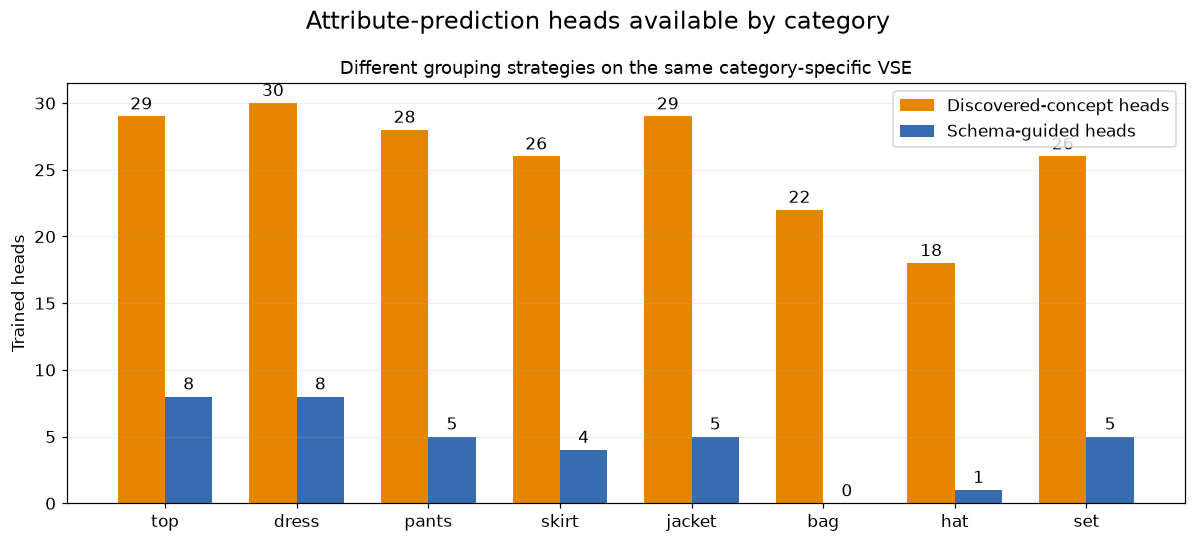

In [2]:
cats=['top','dress','pants','skirt','jacket','bag','hat','set']
head_rows=[]
for cat in cats:
    status=json.loads((MODEL_ROOT/cat/'status.json').read_text(encoding='utf-8'))
    schema_meta=json.loads((MODEL_ROOT/cat/'schema_heads_metadata.json').read_text(encoding='utf-8'))
    head_rows.append({'category':cat,'discovered_heads':status.get('heads',0),'schema_heads':len(schema_meta),
                      'schema_values':sum(len(h['attributes']) for h in schema_meta)})
heads=pd.DataFrame(head_rows); heads.to_csv(FIG_DIR/'3_8_1_available_heads.csv',index=False,encoding='utf-8-sig')
display(heads)
fig,ax=plt.subplots(figsize=(11,5)); x=np.arange(len(heads)); w=.36
ax.bar(x-w/2,heads.discovered_heads,w,label='Discovered-concept heads',color=COLORS['discovered'])
ax.bar(x+w/2,heads.schema_heads,w,label='Schema-guided heads',color=COLORS['schema'])
ax.set_xticks(x,heads.category); ax.set_ylabel('Trained heads'); ax.legend(); ax.grid(axis='y',alpha=.2)
for c in ax.containers: ax.bar_label(c,padding=2)
ax.set_title('Different grouping strategies on the same category-specific VSE')
fig.suptitle('Attribute-prediction heads available by category')
fig.tight_layout(); savefig(fig,'figure_3_8_1_available_heads')

## 3.8.2 Prediction outcomes and abstention

,status,schema,discovered
0,abstained_no_standard_attribute,1223,9029
1,no_category_model,294,294
2,no_trained_attribute_heads,553,0
3,predicted_unvalidated,8728,1475


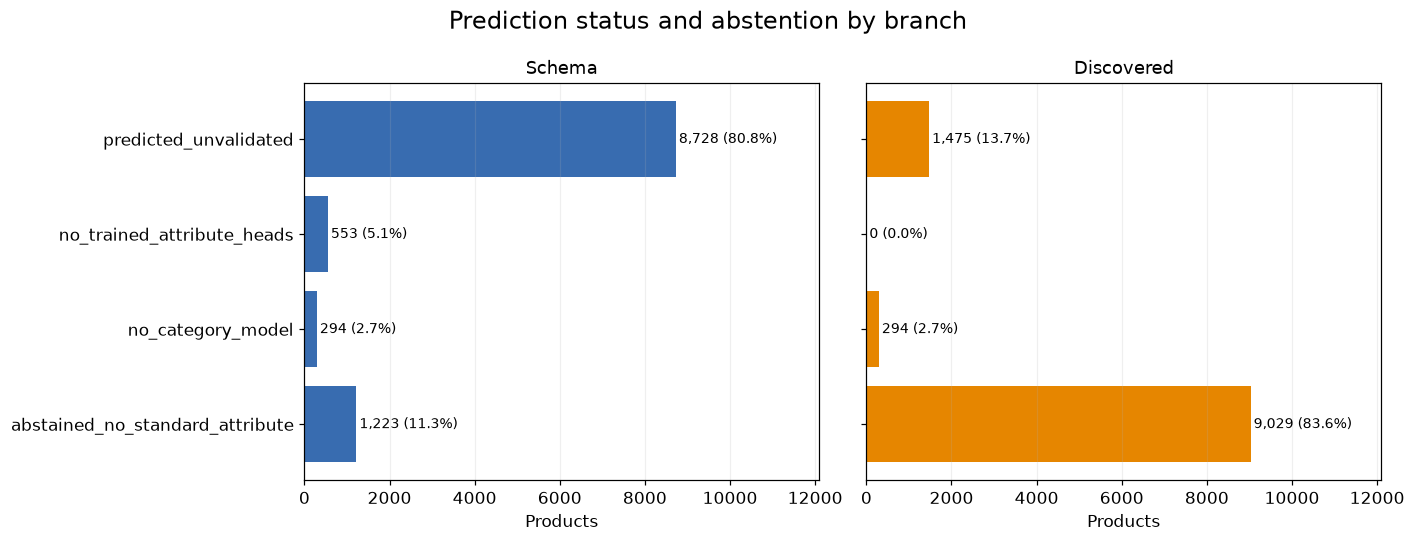

In [3]:
statuses=sorted(set(schema_summary['status_counts'])|set(disc_summary['status_counts']))
outcome=pd.DataFrame({'status':statuses,
 'schema':[schema_summary['status_counts'].get(s,0) for s in statuses],
 'discovered':[disc_summary['status_counts'].get(s,0) for s in statuses]})
outcome.to_csv(FIG_DIR/'3_8_2_prediction_outcomes.csv',index=False,encoding='utf-8-sig'); display(outcome)
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,branch,color in zip(axes,['schema','discovered'],[COLORS['schema'],COLORS['discovered']]):
    vals=outcome[branch]; bars=ax.barh(outcome.status,vals,color=color); ax.set_title(branch.capitalize()); ax.set_xlabel('Products')
    for b,v in zip(bars,vals): ax.text(v+70,b.get_y()+b.get_height()/2,f'{v:,} ({100*v/len(schema_rows):.1f}%)',va='center',fontsize=9)
    ax.set_xlim(0,len(schema_rows)*1.12); ax.grid(axis='x',alpha=.2)
fig.suptitle('Prediction status and abstention by branch')
fig.tight_layout(); savefig(fig,'figure_3_8_2_prediction_outcomes')

## 3.8.3 Candidate coverage by category

,category,products,schema_products,discovered_products,schema_rate,discovered_rate
0,bag,553,0,0,0.000,0.000
1,dress,2316,1992,335,0.860,0.145
2,fabric,14,0,0,0.000,0.000
3,hat,535,0,0,0.000,0.000
4,jacket,1506,1402,99,0.931,0.066
5,pants,1422,1393,417,0.980,0.293
6,set,631,543,392,0.861,0.621
7,shoe,4,0,0,0.000,0.000
8,skirt,951,810,0,0.852,0.000
9,top,2590,2588,232,0.999,0.090


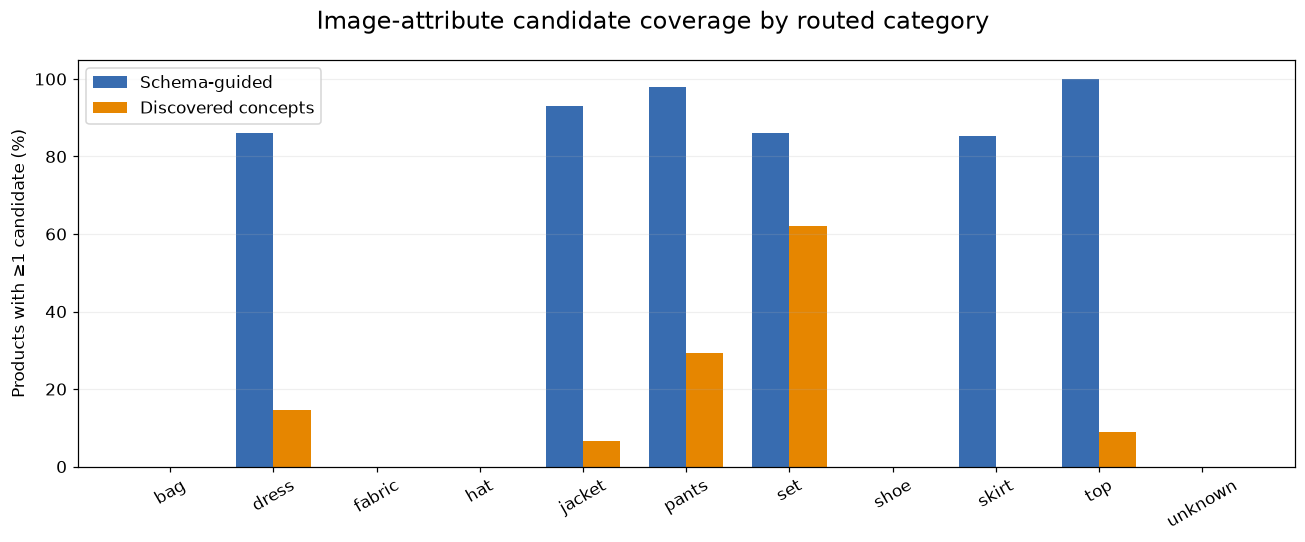

In [4]:
coverage=[]
for cat in sorted(set(r['category_hint'] for r in schema_rows)):
    sr=[r for r in schema_rows if r['category_hint']==cat]; dr=[r for r in disc_rows if r['category_hint']==cat]
    coverage.append({'category':cat,'products':len(sr),
      'schema_products':sum(bool(r['image_candidates']) for r in sr),
      'discovered_products':sum(bool(r['image_candidates']) for r in dr)})
coverage=pd.DataFrame(coverage); coverage['schema_rate']=coverage.schema_products/coverage.products; coverage['discovered_rate']=coverage.discovered_products/coverage.products
coverage.to_csv(FIG_DIR/'3_8_3_category_coverage.csv',index=False,encoding='utf-8-sig'); display(coverage.round(3))
fig,ax=plt.subplots(figsize=(12,5)); x=np.arange(len(coverage)); w=.36
ax.bar(x-w/2,100*coverage.schema_rate,w,label='Schema-guided',color=COLORS['schema'])
ax.bar(x+w/2,100*coverage.discovered_rate,w,label='Discovered concepts',color=COLORS['discovered'])
ax.set_xticks(x,coverage.category,rotation=30); ax.set_ylabel('Products with ≥1 candidate (%)'); ax.legend(); ax.grid(axis='y',alpha=.2)
fig.suptitle('Image-attribute candidate coverage by routed category')
fig.tight_layout(); savefig(fig,'figure_3_8_3_category_coverage')

## 3.8.4 Number of emitted candidates per product

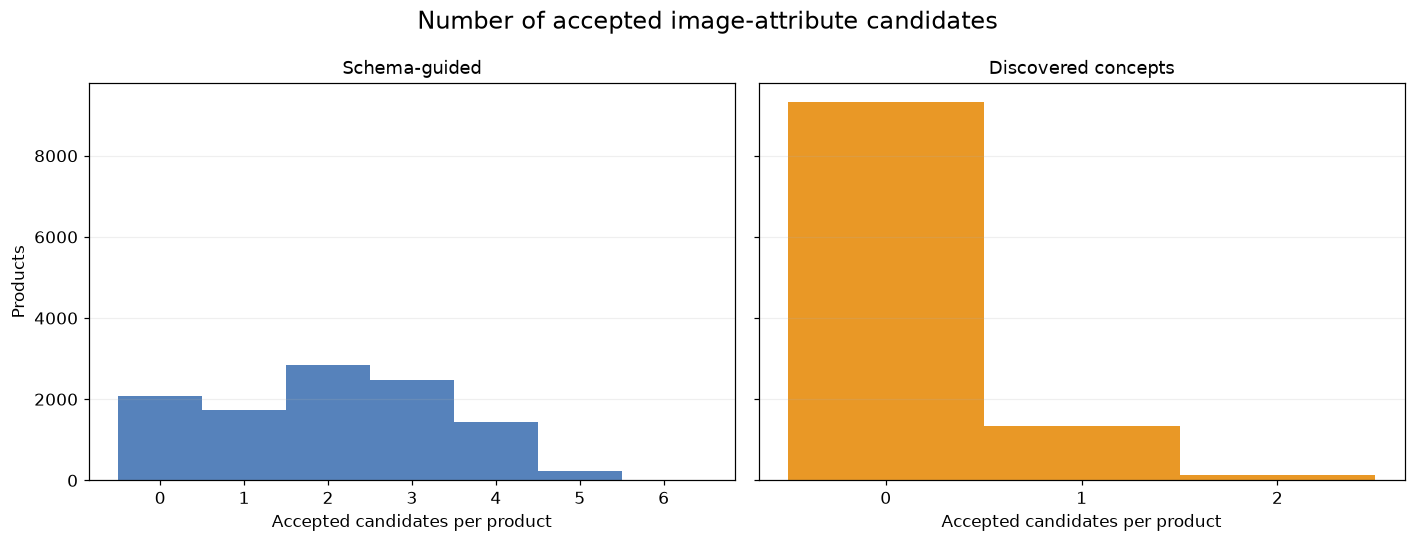

Schema mean=2.02, median=2; discovered mean=0.15, median=0


In [5]:
sc=np.asarray([len(r['image_candidates']) for r in schema_rows]); dc=np.asarray([len(r['image_candidates']) for r in disc_rows])
max_n=max(sc.max(),dc.max()); xs=np.arange(max_n+1)
candidate_counts=pd.DataFrame({'n_candidates':xs,'schema_products':[sum(sc==x) for x in xs],'discovered_products':[sum(dc==x) for x in xs]})
candidate_counts.to_csv(FIG_DIR/'3_8_4_candidates_per_product.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,vals,name,color in zip(axes,[sc,dc],['Schema-guided','Discovered concepts'],[COLORS['schema'],COLORS['discovered']]):
    bins=np.arange(vals.max()+2)-.5; ax.hist(vals,bins=bins,color=color,alpha=.85); ax.set_xticks(range(vals.max()+1)); ax.set_xlabel('Accepted candidates per product'); ax.set_title(name); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('Products'); fig.suptitle('Number of accepted image-attribute candidates')
fig.tight_layout(); savefig(fig,'figure_3_8_4_candidates_per_product')
print(f'Schema mean={sc.mean():.2f}, median={np.median(sc):.0f}; discovered mean={dc.mean():.2f}, median={np.median(dc):.0f}')

## 3.8.5 Standardized attribute groups emitted

,group,schema,discovered
0,color,1294,294
1,fit,5661,183
2,length,3836,100
3,neckline,2563,25
4,pant_cut,600,155
5,pattern,3078,79
6,set_type,447,501
7,sleeve,3097,125
8,waist,1268,154


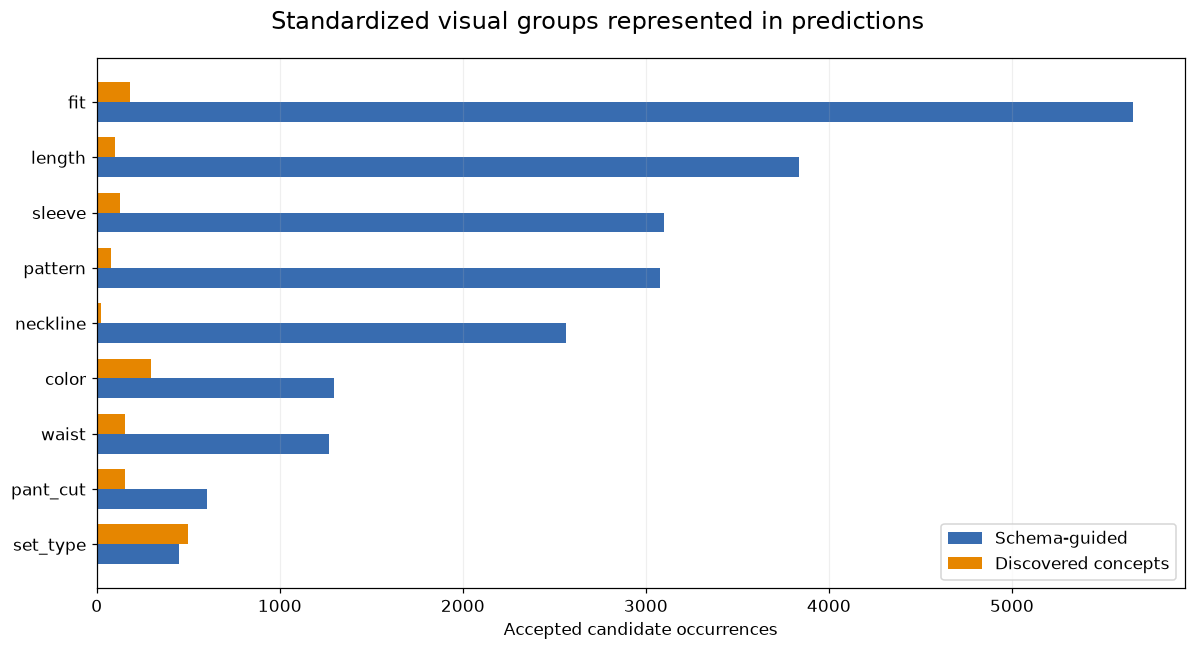

In [6]:
def group_counts(rs): return collections.Counter(c['seed_group_hint'] for r in rs for c in r['image_candidates'])
sg,dg=group_counts(schema_rows),group_counts(disc_rows); groups=sorted(set(sg)|set(dg))
group_df=pd.DataFrame({'group':groups,'schema':[sg[g] for g in groups],'discovered':[dg[g] for g in groups]})
group_df.to_csv(FIG_DIR/'3_8_5_attribute_group_counts.csv',index=False,encoding='utf-8-sig'); display(group_df)
ordered=group_df.sort_values('schema'); y=np.arange(len(ordered)); h=.36
fig,ax=plt.subplots(figsize=(11,6)); ax.barh(y-h/2,ordered.schema,h,label='Schema-guided',color=COLORS['schema']); ax.barh(y+h/2,ordered.discovered,h,label='Discovered concepts',color=COLORS['discovered'])
ax.set_yticks(y,ordered.group); ax.set_xlabel('Accepted candidate occurrences'); ax.legend(); ax.grid(axis='x',alpha=.2)
fig.suptitle('Standardized visual groups represented in predictions')
fig.tight_layout(); savefig(fig,'figure_3_8_5_attribute_groups')

## 3.8.6 Accepted score and runner-up margin

Acceptance requires score ≥ 0.70 and a difference from the runner-up ≥ 0.15. These are heuristic, uncalibrated thresholds. The distributions below include accepted standardized candidates only.

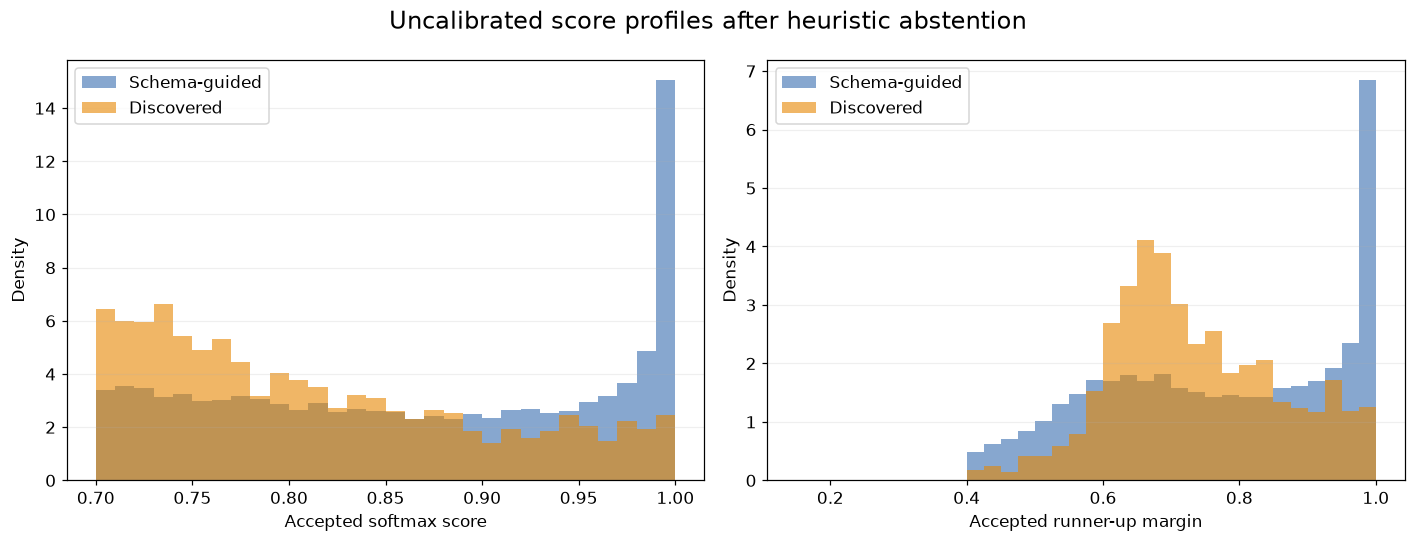

In [7]:
def candidate_values(rs,key): return np.asarray([c[key] for r in rs for c in r['image_candidates']])
ss,ds=candidate_values(schema_rows,'score'),candidate_values(disc_rows,'score'); sm,dm=candidate_values(schema_rows,'runner_up_margin'),candidate_values(disc_rows,'runner_up_margin')
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].hist(ss,bins=np.linspace(.7,1,31),density=True,alpha=.6,label='Schema-guided',color=COLORS['schema']); axes[0].hist(ds,bins=np.linspace(.7,1,31),density=True,alpha=.6,label='Discovered',color=COLORS['discovered']); axes[0].set_xlabel('Accepted softmax score'); axes[0].set_ylabel('Density'); axes[0].legend()
axes[1].hist(sm,bins=np.linspace(.15,1,35),density=True,alpha=.6,label='Schema-guided',color=COLORS['schema']); axes[1].hist(dm,bins=np.linspace(.15,1,35),density=True,alpha=.6,label='Discovered',color=COLORS['discovered']); axes[1].set_xlabel('Accepted runner-up margin'); axes[1].set_ylabel('Density'); axes[1].legend()
for ax in axes: ax.grid(axis='y',alpha=.2)
fig.suptitle('Uncalibrated score profiles after heuristic abstention')
fig.tight_layout(); savefig(fig,'figure_3_8_6_score_margin_distributions')

## 3.8.7 Cross-branch overlap and exact candidate agreement

,outcome,products
0,Schema only,7328
1,Both branches,1400
2,Discovered only,75
3,Neither branch,1995


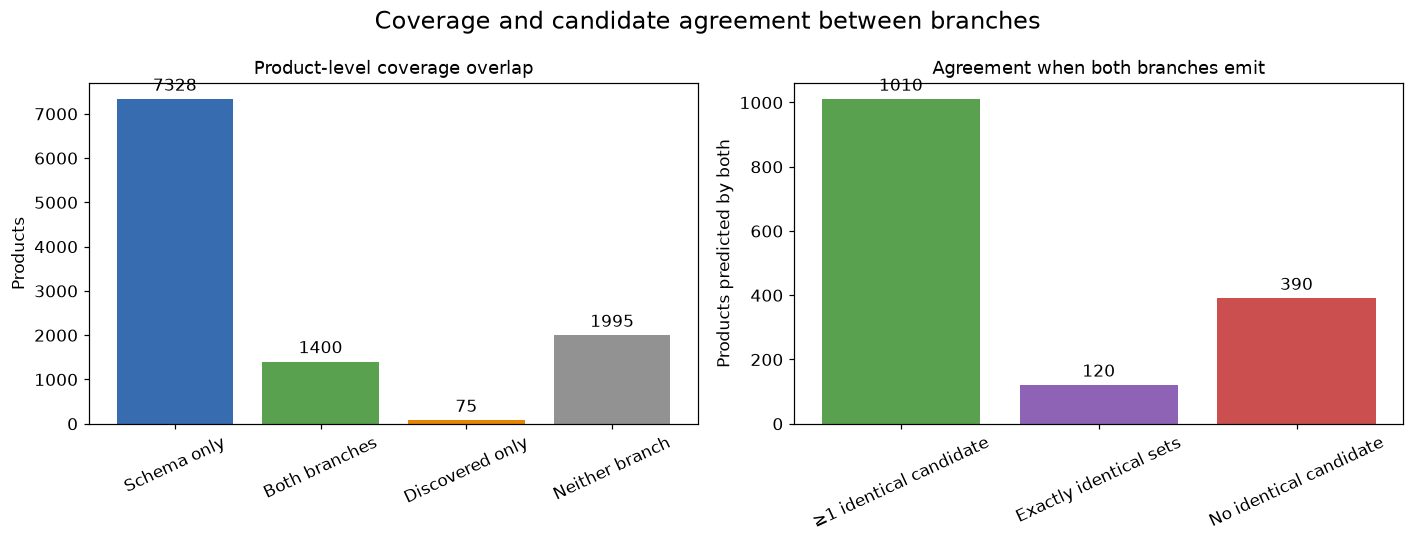

Mean Jaccard among products covered by both: 0.319


In [8]:
only_s=only_d=both=neither=exact_nonempty=shared_attr=0; jaccards=[]
for pid,sr in schema_by_id.items():
    dr=disc_by_id[pid]; S={(c['seed_group_hint'],c['attribute']) for c in sr['image_candidates']}; D={(c['seed_group_hint'],c['attribute']) for c in dr['image_candidates']}
    if S and D:
        both+=1; exact_nonempty+=S==D; shared_attr+=bool(S&D); jaccards.append(len(S&D)/len(S|D))
    elif S: only_s+=1
    elif D: only_d+=1
    else: neither+=1
overlap=pd.DataFrame({'outcome':['Schema only','Both branches','Discovered only','Neither branch'],
                      'products':[only_s,both,only_d,neither]})
overlap.to_csv(FIG_DIR/'3_8_7_cross_branch_overlap.csv',index=False,encoding='utf-8-sig'); display(overlap)
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].bar(overlap.outcome,overlap.products,color=[COLORS['schema'],COLORS['green'],COLORS['discovered'],COLORS['gray']]); axes[0].tick_params(axis='x',rotation=25); axes[0].set_ylabel('Products'); axes[0].set_title('Product-level coverage overlap')
for c in axes[0].containers: axes[0].bar_label(c,padding=3)
agreement=[shared_attr,exact_nonempty,both-shared_attr]; labels=['≥1 identical candidate','Exactly identical sets','No identical candidate']
axes[1].bar(labels,agreement,color=[COLORS['green'],COLORS['purple'],COLORS['red']]); axes[1].tick_params(axis='x',rotation=25); axes[1].set_ylabel('Products predicted by both'); axes[1].set_title('Agreement when both branches emit')
for c in axes[1].containers: axes[1].bar_label(c,padding=3)
fig.suptitle('Coverage and candidate agreement between branches')
fig.tight_layout(); savefig(fig,'figure_3_8_7_cross_branch_agreement')
print(f'Mean Jaccard among products covered by both: {np.mean(jaccards):.3f}')

## 3.8.8 Review flags generated by each branch

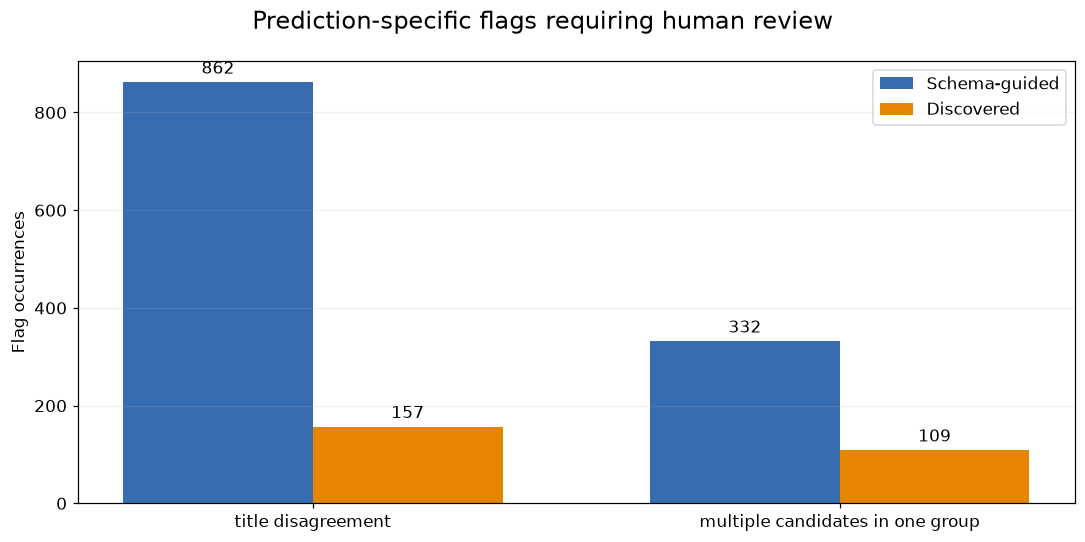

In [9]:
def prediction_flags(rs):
    c=collections.Counter()
    for r in rs:
        for f in r['flags']:
            if f.startswith('image_title_disagreement:'): c['title disagreement']+=1
            elif f.startswith('multiple_image_candidates:'): c['multiple candidates in one group']+=1
    return c
sf,df=prediction_flags(schema_rows),prediction_flags(disc_rows); names=['title disagreement','multiple candidates in one group']
flag_df=pd.DataFrame({'flag':names,'schema':[sf[n] for n in names],'discovered':[df[n] for n in names]})
flag_df.to_csv(FIG_DIR/'3_8_8_review_flags.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,5)); x=np.arange(len(names)); w=.36
ax.bar(x-w/2,flag_df.schema,w,label='Schema-guided',color=COLORS['schema']); ax.bar(x+w/2,flag_df.discovered,w,label='Discovered',color=COLORS['discovered'])
ax.set_xticks(x,names); ax.set_ylabel('Flag occurrences'); ax.legend(); ax.grid(axis='y',alpha=.2)
for c in ax.containers: ax.bar_label(c,padding=3)
fig.suptitle('Prediction-specific flags requiring human review')
fig.tight_layout(); savefig(fig,'figure_3_8_8_review_flags')

## Report-ready synthesis and exported files

In [10]:
print('REPORT-READY SYNTHESIS')
print(f"At the fixed uncalibrated threshold of {schema_summary['threshold']:.2f} and runner-up margin of {schema_summary['margin']:.2f}, the schema-guided branch emitted at least one standardized image-attribute candidate for {schema_summary['products_with_image_candidates']:,} of {len(schema_rows):,} products ({100*schema_summary['products_with_image_candidates']/len(schema_rows):.1f}%). The discovered-concept branch covered {disc_summary['products_with_image_candidates']:,} products ({100*disc_summary['products_with_image_candidates']/len(schema_rows):.1f}%). This difference reflects grouping and standardization behavior as well as model scores; it cannot establish which branch is more accurate without independent gold labels. Products predicted by both branches showed a mean exact-candidate-set Jaccard similarity of {np.mean(jaccards):.3f}.")
print('\nGenerated files:')
for p in sorted(FIG_DIR.iterdir()): print(' -',p.relative_to(ROOT))

REPORT-READY SYNTHESIS
At the fixed uncalibrated threshold of 0.70 and runner-up margin of 0.15, the schema-guided branch emitted at least one standardized image-attribute candidate for 8,728 of 10,798 products (80.8%). The discovered-concept branch covered 1,475 products (13.7%). This difference reflects grouping and standardization behavior as well as model scores; it cannot establish which branch is more accurate without independent gold labels. Products predicted by both branches showed a mean exact-candidate-set Jaccard similarity of 0.319.

Generated files:
 - outputs\figures\prediction_branches\3_8_1_available_heads.csv
 - outputs\figures\prediction_branches\3_8_2_prediction_outcomes.csv
 - outputs\figures\prediction_branches\3_8_3_category_coverage.csv
 - outputs\figures\prediction_branches\3_8_4_candidates_per_product.csv
 - outputs\figures\prediction_branches\3_8_5_attribute_group_counts.csv
 - outputs\figures\prediction_branches\3_8_7_cross_branch_overlap.csv
 - outputs\figu